# 121 · why does per-box normalization help?
transformer2 `--norm box`: x̃ = (x − mean[box,l,f,c]) / std[box,l,f,c] over train samples. ID IoU@0.08 at 200ep: box .623 > laser_z .584 > sample_z .556 = sample_std .556.
**Input x** (src9/dataset.py `process_x`): tukey-windowed rfft of the raw shifts, **linear magnitude |X|** (not log, not power), divided by the sample's own std over (L,F,C). Shape (L=100, F=1170, C=2).
Sections: **1** load · **2** variance decomposition · **3** CV of box stats (what the std division does) · **4** linear probes across normalizations · **5** drift of the per-sample spectrum.

In [1]:
import sys, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from PIL import Image
sys.path.insert(0, '..')
from src9.dataset import load_splits, load_fft
plt.rcParams['figure.figsize'] = (18, 4.5)
samples, idxs = load_splits()
dirs, metas = list(samples), list(samples.values())

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

## 1 · load ~1800 train samples (600 per box), raw x exactly as process_x makes it

In [2]:
rng = random.Random(0)
train = idxs['train']
by_box = {}
for i in train: by_box.setdefault(metas[i]['box'], []).append(i)
pick = sorted(sum([rng.sample(v, min(600, len(v))) for v in by_box.values()], []))
print({b: len(v) for b, v in by_box.items()}, len(pick))

def load(i):
    x = load_fft(dirs[i], metas[i], 'tukey').abs()
    x = (x / x.std()).numpy().astype(np.float32)
    m = np.asarray(Image.open(dirs[i] / 'image/03_smask.png').convert('F').resize((32, 32), Image.BOX), np.float32) / 255
    return x, m
with ThreadPoolExecutor(16) as ex: out = list(ex.map(load, pick))
X = np.stack([o[0] for o in out]); M = np.stack([o[1] for o in out]); del out
df = pd.DataFrame([dict(box=metas[i]['box'], exp=metas[i]['experiment'], pos=metas[i]['position_id'], spk=metas[i]['speaker'],
                        layout=metas[i]['layout'], n_obj=metas[i]['n_objects'],
                        com_r=metas[i]['coms'][0][0][0] / metas[i]['crop_overhead_shape'][0] if metas[i]['n_objects'] == 1 else np.nan,
                        com_c=metas[i]['coms'][0][0][1] / metas[i]['crop_overhead_shape'][1] if metas[i]['n_objects'] == 1 else np.nan) for i in pick])
S, L, F, Cc = X.shape
print(X.shape, f'{X.nbytes / 1e9:.2f} GB'); print(df.groupby('box').n_obj.value_counts().unstack())

{'gastronorm': 2547, 'green-plastic': 3587, 'cardboard': 5085} 1800


(1800, 100, 1170, 2) 1.68 GB
n_obj          0    1   2
box                      
cardboard      8  536  56
gastronorm     7  524  69
green-plastic  7  541  52


## 2 · variance decomposition of raw x
Constants (same for every sample of a box): box mean, box×bin shape (mean over s,l), box×laser offset (mean over s,f), box×laser×bin interaction. Then the sample-varying residual r = x − mean_s[box,l,f,c], split into per-sample global level, per-sample laser level (s,l,c), per-sample spectrum (s,f,c), and the rest.

fraction of total variance (raw x):
box_mean               0.0025
box_bin_shape          0.6246
box_laser_offset       0.0475
box_laser_bin_inter    0.2405
sample_varying         0.1235   sum 1.0385

sample-varying part, split:
sample_level          0.0093
sample_laser_level    0.0164
sample_spectrum       0.5624
rest                  0.4171


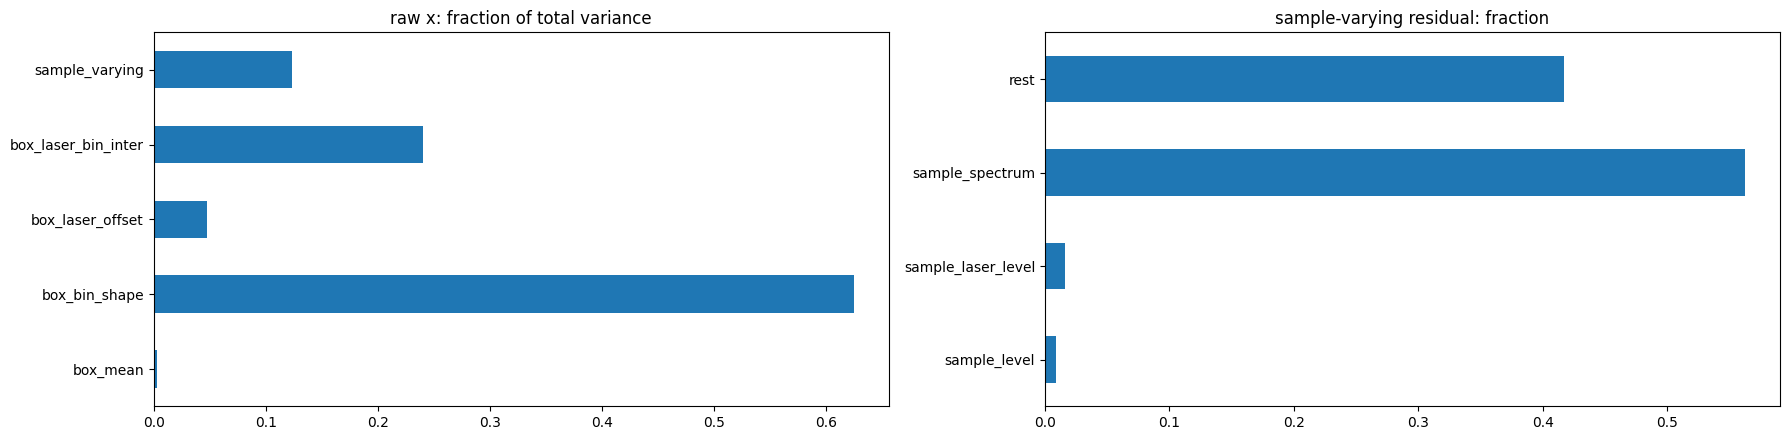

In [3]:
boxes = sorted(df.box.unique()); bidx = df.box.map({b: k for k, b in enumerate(boxes)}).values
gm = X.mean(dtype=np.float64)
tot = ((X - gm) ** 2).sum(dtype=np.float64)
ss = dict(box_mean=0., box_channel=0., box_bin_shape=0., box_laser_offset=0., box_laser_bin_inter=0., sample_varying=0.)
rs = dict(sample_level=0., sample_channel=0., sample_laser_level=0., sample_spectrum=0., rest=0.)
MU = np.zeros((len(boxes), L, F, Cc), np.float32); SD = np.zeros_like(MU)
for k, b in enumerate(boxes):
    xb = X[bidx == k]; n = len(xb)
    mu = xb.mean(0); MU[k] = mu; SD[k] = xb.std(0)
    m0 = mu.mean(); ch = mu.mean((0, 1), keepdims=True) - m0; shp = mu.mean(0, keepdims=True) - m0 - ch; las = mu.mean(1, keepdims=True) - m0 - ch; inter = mu - m0 - ch - shp - las
    ss['box_channel'] += n * L * F * (ch.astype(np.float64) ** 2).sum()
    ss['box_mean'] += n * L * F * Cc * (m0 - gm) ** 2
    ss['box_bin_shape'] += n * L * (shp.astype(np.float64) ** 2).sum()
    ss['box_laser_offset'] += n * F * (las.astype(np.float64) ** 2).sum()
    ss['box_laser_bin_inter'] += n * (inter.astype(np.float64) ** 2).sum()
    r = xb - mu
    ss['sample_varying'] += (r.astype(np.float64) ** 2).sum()
    g = r.mean((1, 2, 3), keepdims=True); c_ = r.mean((1, 2), keepdims=True) - g; a = r.mean(2, keepdims=True) - g - c_; s_ = r.mean(1, keepdims=True) - g - c_
    rs['sample_channel'] += L * F * (c_.astype(np.float64) ** 2).sum()
    rs['sample_level'] += L * F * Cc * (g.astype(np.float64) ** 2).sum()
    rs['sample_laser_level'] += F * (a.astype(np.float64) ** 2).sum()
    rs['sample_spectrum'] += L * (s_.astype(np.float64) ** 2).sum()
    rs['rest'] += ((r - g - c_ - a - s_).astype(np.float64) ** 2).sum()
    del r, xb
vf = pd.Series(ss) / tot; rf = pd.Series(rs) / ss['sample_varying']
print('fraction of total variance (raw x):'); print(vf.round(4).to_string(), '  sum', round(vf.sum(), 4))
print('\nsample-varying part, split:'); print(rf.round(4).to_string())
fig, ax = plt.subplots(1, 2); vf.plot.barh(ax=ax[0], title='raw x: fraction of total variance'); rf.plot.barh(ax=ax[1], title='sample-varying residual: fraction')
plt.tight_layout(); plt.show()

### per-box: where the variance lives, in linear |X| vs log|X|

In [4]:
def decomp(Z):
    rows = []
    for k, b in enumerate(boxes):
        z = Z[bidx == k]; mu = z.mean(0); t = ((z - z.mean()) ** 2).sum(dtype=np.float64)
        rows.append(dict(box=b, const_frac=len(z) * ((mu - z.mean()).astype(np.float64) ** 2).sum() / t,
                         laser_offset_of_const=((mu.mean(1) - mu.mean()) ** 2).sum() * F / ((mu - mu.mean()) ** 2).sum(),
                         bin_shape_of_const=((mu.mean(0) - mu.mean()) ** 2).sum() * L / ((mu - mu.mean()) ** 2).sum()))
    return pd.DataFrame(rows).set_index('box').round(3)
print('linear |X|'); print(decomp(X))
print('log |X|'); print(decomp(np.log(X + 1e-3)))

linear |X|


               const_frac  laser_offset_of_const  bin_shape_of_const
box                                                                 
cardboard           0.935                  0.095                0.75
gastronorm          0.841                  0.019                0.66
green-plastic       0.852                  0.044                0.73
log |X|


               const_frac  laser_offset_of_const  bin_shape_of_const
box                                                                 
cardboard           0.812                  0.148               0.779
gastronorm          0.825                  0.087               0.729
green-plastic       0.797                  0.106               0.841


## 3 · what the box std division does: std vs mean per (box,l,f,c)
If std ∝ mean (constant CV), (x − m)/s = (x/m − 1)/CV ≈ log(x/m)/CV: box norm turns linear |X| into a *relative* (dB-like) change vs the box's reference spectrum, so every bin and laser lands on the same scale.

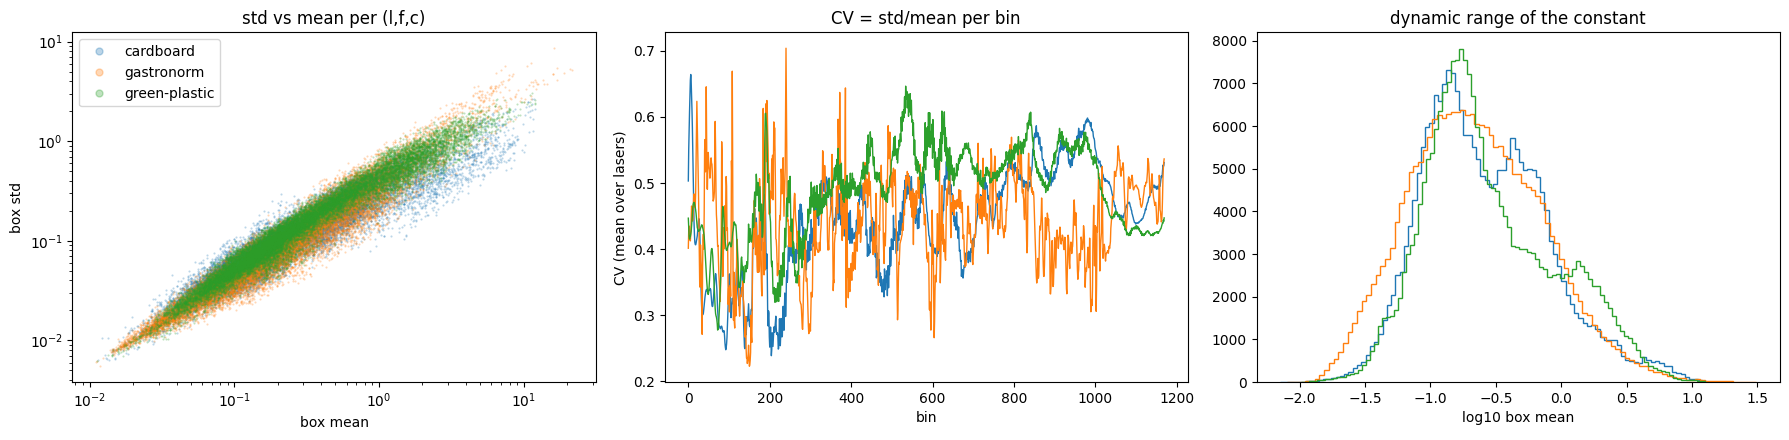

cardboard    corr(log mean, log std)=0.945  slope=0.78  CV median=0.44 p5-p95=0.20-0.69  mean range p1-p99 = 171x
gastronorm   corr(log mean, log std)=0.964  slope=0.92  CV median=0.44 p5-p95=0.24-0.65  mean range p1-p99 = 190x
green-plastic corr(log mean, log std)=0.978  slope=0.90  CV median=0.49 p5-p95=0.29-0.67  mean range p1-p99 = 130x


In [5]:
cv = SD / MU
fig, ax = plt.subplots(1, 3)
for k, b in enumerate(boxes):
    sel = np.random.default_rng(0).choice(MU[k].size, 20000, replace=False)
    ax[0].loglog(MU[k].ravel()[sel], SD[k].ravel()[sel], '.', ms=1, alpha=.3, label=b)
    ax[1].plot(cv[k].mean((0, 2)), label=b, lw=1)
    ax[2].hist(np.log10(MU[k].ravel()), 100, histtype='step', label=b)
ax[0].set(xlabel='box mean', ylabel='box std', title='std vs mean per (l,f,c)'); ax[0].legend(markerscale=10)
ax[1].set(xlabel='bin', ylabel='CV (mean over lasers)', title='CV = std/mean per bin'); ax[2].set(xlabel='log10 box mean', title='dynamic range of the constant')
plt.tight_layout(); plt.show()
for k, b in enumerate(boxes):
    lm, ls = np.log(MU[k]).ravel(), np.log(SD[k]).ravel()
    print(f'{b:12s} corr(log mean, log std)={np.corrcoef(lm, ls)[0,1]:.3f}  slope={np.polyfit(lm, ls, 1)[0]:.2f}  CV median={np.median(cv[k]):.2f} p5-p95={np.percentile(cv[k],5):.2f}-{np.percentile(cv[k],95):.2f}'
          f'  mean range p1-p99 = {np.percentile(MU[k],99)/np.percentile(MU[k],1):.0f}x')

## 4 · linear probes across normalizations
Features: mean over 65-bin bands → (L=100, 18 bands, C=2) = 3,600. Normalization applied at full resolution first, then pooled. Box stats from this subset (all of it; target-free).
Targets: CoM (row, col) of single-object samples; top-8 PCA coefficients of the 32×32 mask (all non-empty samples). GroupKFold(5) by (experiment, position). RidgeCV, with and without per-feature standardization (StandardScaler makes the probe blind to per-feature scale; the unscaled probe is closer to what a shared embedding sees).
- (a) raw · (b) sample_z · (c) laser_z · (d) box mean-only · (e) box mean/std · (f) per-(box,laser,c) offset removal only · (g) per-(box,f,c) shape removal only · (h) log|X| − box mean of log|X| (log-ratio) · (i) box mean/std then per-(box,l,c) std (no per-bin reweighting)

In [6]:
band = 65; nb = F // band
pool = lambda Z: Z[:, :, :nb * band].reshape(len(Z), L, nb, band, Cc).mean(3).reshape(len(Z), -1)
eps = 1e-6
LMU = np.zeros_like(MU)
for k in range(len(boxes)): LMU[k] = np.log(X[bidx == k] + 1e-3).mean(0)
LASOFF = MU.mean(2, keepdims=True)                       # (nb,L,1,C): per-(box,laser,c) mean over bins and samples
SHAPE = MU.mean(1, keepdims=True)                        # (nb,1,F,C): per-(box,f,c) mean over lasers and samples
SDL = np.sqrt(((SD ** 2)).mean(2, keepdims=True))        # (nb,L,1,C): per-(box,laser,c) rms std
norms = {
 'a_raw':        lambda x, k: x,
 'b_sample_z':   lambda x, k: (x - x.mean((1,2,3), keepdims=True)) / (x.std((1,2,3), keepdims=True) + eps),
 'c_laser_z':    lambda x, k: (x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + eps),
 'd_box_mean':   lambda x, k: x - MU[k],
 'e_box_z':      lambda x, k: (x - MU[k]) / SD[k],
 'f_laser_off':  lambda x, k: x - LASOFF[k],
 'g_bin_shape':  lambda x, k: x - SHAPE[k],
 'h_log_ratio':  lambda x, k: np.log(x + 1e-3) - LMU[k],
 'i_box_mean_laserstd': lambda x, k: (x - MU[k]) / SDL[k],
}
feats = {}
for name, fn in norms.items():
    Fm = np.zeros((S, L * nb * Cc), np.float32)
    for k in range(len(boxes)):
        ii = np.where(bidx == k)[0]
        for j in range(0, len(ii), 200): Fm[ii[j:j+200]] = pool(fn(X[ii[j:j+200]], k))
    feats[name] = Fm
print({k: v.shape for k, v in feats.items()})

{'a_raw': (1800, 3600), 'b_sample_z': (1800, 3600), 'c_laser_z': (1800, 3600), 'd_box_mean': (1800, 3600), 'e_box_z': (1800, 3600), 'f_laser_off': (1800, 3600), 'g_bin_shape': (1800, 3600), 'h_log_ratio': (1800, 3600), 'i_box_mean_laserstd': (1800, 3600)}


In [7]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score
groups = (df.exp + '_' + df.pos.astype(str)).values
one = np.where(df.n_obj == 1)[0]; nonempty = np.where(df.n_obj > 0)[0]
Y_com = df[['com_r', 'com_c']].values[one]
Mf = M.reshape(S, -1)[nonempty]
alphas = np.logspace(-3, 6, 19)

def probe(Fm, rows, Y, scale, pca_mask=False):
    pred = np.zeros_like(Y, dtype=np.float64) if not pca_mask else None; ys, ps = [], []
    for tr, te in GroupKFold(5).split(rows, groups=groups[rows]):
        Ytr, Yte = Y[tr], Y[te]
        if pca_mask: p = PCA(8).fit(Ytr); Ytr, Yte = p.transform(Ytr), p.transform(Yte)
        m = make_pipeline(StandardScaler(), RidgeCV(alphas)) if scale else make_pipeline(StandardScaler(with_std=False), RidgeCV(alphas))
        m.fit(Fm[rows][tr], Ytr); ys.append(Yte); ps.append(m.predict(Fm[rows][te]))
    return r2_score(np.concatenate(ys), np.concatenate(ps))   # uniform average over targets
res = []
for name, Fm in feats.items():
    for scale in (False, True):
        res.append(dict(norm=name, scaled=scale, com_R2=probe(Fm, one, Y_com, scale), maskpca8_R2=probe(Fm, nonempty, Mf, scale, True)))
R = pd.DataFrame(res).pivot(index='norm', columns='scaled', values=['com_R2', 'maskpca8_R2']).round(3)
R

com_R2        maskpca8_R2       
scaled               False  True        False  True 
norm                                                
a_raw                0.694  0.713       0.493  0.525
b_sample_z           0.692  0.718       0.493  0.522
c_laser_z            0.703  0.699       0.510  0.506
d_box_mean           0.686  0.718       0.476  0.513
e_box_z              0.723  0.726       0.544  0.542
f_laser_off          0.693  0.698       0.493  0.520
g_bin_shape          0.694  0.719       0.494  0.530
h_log_ratio          0.697  0.695       0.531  0.538
i_box_mean_laserstd  0.678  0.708       0.490  0.515

### per box (CoM, scaled ridge): does the ranking hold inside each box, or is it about pooling boxes?

In [8]:
rows_ = []
for name in ['a_raw', 'b_sample_z', 'c_laser_z', 'd_box_mean', 'e_box_z', 'f_laser_off', 'g_bin_shape', 'h_log_ratio']:
    r = dict(norm=name)
    for k, b in enumerate(boxes):
        sub = one[bidx[one] == k]
        Ys = df[['com_r', 'com_c']].values[sub]; ys, ps = [], []
        for tr, te in GroupKFold(5).split(sub, groups=groups[sub]):
            m = make_pipeline(StandardScaler(), RidgeCV(alphas)).fit(feats[name][sub][tr], Ys[tr]); ys.append(Ys[te]); ps.append(m.predict(feats[name][sub][te]))
        r[b] = r2_score(np.concatenate(ys), np.concatenate(ps))
    rows_.append(r)
pd.DataFrame(rows_).set_index('norm').round(3)

,cardboard,gastronorm,green-plastic
norm,,,
a_raw,0.678,0.856,0.878
b_sample_z,0.675,0.835,0.879
c_laser_z,0.676,0.841,0.871
d_box_mean,0.678,0.856,0.878
e_box_z,0.678,0.864,0.878
f_laser_off,0.678,0.856,0.878
g_bin_shape,0.678,0.856,0.878
h_log_ratio,0.696,0.861,0.881


### conditioning: how much of each input's variance is object-related? (fraction of feature variance that's between positions, and the share of the unscaled input energy carried by the constants)

In [9]:
rows_ = []
for name, Fm in feats.items():
    tot_e = (Fm.astype(np.float64) ** 2).sum()                                   # energy the embedding sees (incl. constants)
    var = ((Fm - Fm.mean(0)) ** 2).sum(dtype=np.float64)
    within_box = sum(((Fm[bidx == k] - Fm[bidx == k].mean(0)) ** 2).sum(dtype=np.float64) for k in range(len(boxes)))
    g = pd.Series(groups); pos_mean = pd.DataFrame(Fm).groupby(g.values).transform('mean').values
    between_pos = ((pos_mean - np.stack([Fm[bidx == k].mean(0) for k in range(len(boxes))])[bidx]) ** 2).sum(dtype=np.float64)
    # feature-scale spread: ratio of p95/p5 per-feature std (how unequal the features are)
    sd = Fm.std(0)
    rows_.append(dict(norm=name, varying_share_of_energy=within_box / tot_e, between_pos_share_of_within_box=between_pos / within_box,
                      feat_std_p95_over_p5=np.percentile(sd, 95) / np.percentile(sd, 5)))
pd.DataFrame(rows_).set_index('norm').round(3)

,varying_share_of_energy,between_pos_share_of_within_box,feat_std_p95_over_p5
norm,,,
a_raw,0.036,0.763,28.819000
b_sample_z,0.051,0.764,15.799000
c_laser_z,0.301,0.770,3.241000
d_box_mean,1.000,0.763,13.303000
e_box_z,1.000,0.769,1.643000
f_laser_off,0.057,0.763,13.571000
g_bin_shape,0.180,0.763,21.353001
h_log_ratio,1.000,0.758,2.395000
i_box_mean_laserstd,1.000,0.778,10.480000


## 5 · drift: the per-sample spectrum (laser-averaged residual) — speaker vs position
r = x − box mean; s(f,c) = mean over lasers of r (pooled to 18 bands). How much of its variance is speaker, layout, position? And CoM R² from s alone vs from the laser-varying rest.

per-sample spectrum (laser-avg) variance explained by: {'spk': np.float32(0.391), 'layout': np.float32(0.036), 'exp+pos': np.float32(0.752)}
laser-varying part variance explained by:            {'spk': np.float32(0.223), 'layout': np.float32(0.061), 'exp+pos': np.float32(0.775)}
energy: spectrum part 0.496 of the box-mean residual, laser-varying 0.504
CoM R2 from spectrum only (36): 0.116


CoM R2 from laser-varying (3600): 0.716


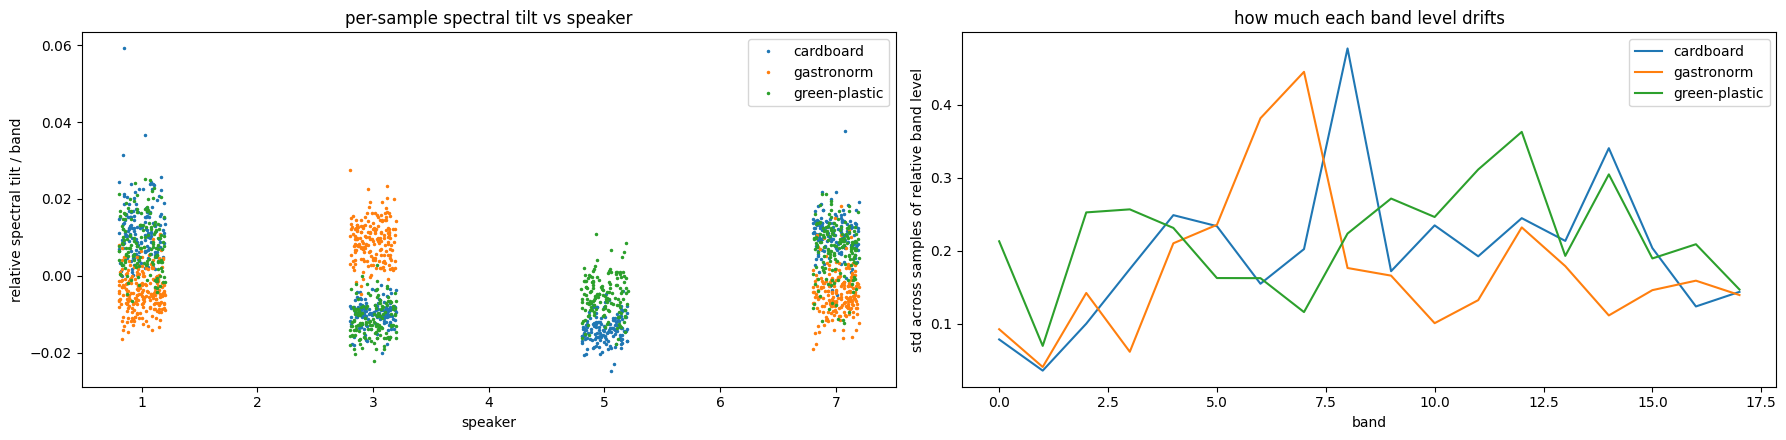

tilt variance explained by: {'spk': np.float64(0.239), 'layout': np.float64(0.034), 'exp+pos': np.float64(0.754)}


In [10]:
Rb = feats['d_box_mean'].reshape(S, L, nb, Cc)
spec = Rb.mean(1).reshape(S, -1)                              # (S, 36) per-sample spectral deviation
lasvar = (Rb - Rb.mean(1, keepdims=True)).reshape(S, -1)       # laser-varying part
def eta2(Z, keys):
    Z = Z - pd.DataFrame(Z).groupby(df.box.values).transform('mean').values
    t = (Z ** 2).sum(); out = {}
    for k in keys:
        g = df[k].astype(str).values if isinstance(k, str) else (df[k[0]].astype(str) + '_' + df[k[1]].astype(str)).values
        out[k if isinstance(k, str) else '+'.join(k)] = (pd.DataFrame(Z).groupby(g).transform('mean').values ** 2).sum() / t
    return out
print('per-sample spectrum (laser-avg) variance explained by:', {k: round(v, 3) for k, v in eta2(spec, ['spk', 'layout', ('exp', 'pos')]).items()})
print('laser-varying part variance explained by:           ', {k: round(v, 3) for k, v in eta2(lasvar, ['spk', 'layout', ('exp', 'pos')]).items()})
print(f'energy: spectrum part {(spec**2).sum() * L / (Rb**2).sum():.3f} of the box-mean residual, laser-varying {(lasvar**2).sum() / (Rb**2).sum():.3f}')
for nm, Fm in [('spectrum only (36)', spec), ('laser-varying (3600)', lasvar)]:
    ys, ps = [], []
    for tr, te in GroupKFold(5).split(one, groups=groups[one]):
        m = make_pipeline(StandardScaler(), RidgeCV(alphas)).fit(Fm[one][tr], Y_com[tr]); ys.append(Y_com[te]); ps.append(m.predict(Fm[one][te]))
    print(f'CoM R2 from {nm}: {r2_score(np.concatenate(ys), np.concatenate(ps)):.3f}')
# spectral tilt per sample: slope of the relative band deviation vs band index, laser-averaged, x channel+y channel
rel = (Rb / feats['a_raw'].reshape(S, L, nb, Cc).mean(0, keepdims=True).clip(1e-6)).mean((1, 3))   # relative deviation per band
tilt = np.polyfit(np.arange(nb), rel.T, 1)[0]
df['tilt'] = tilt
fig, ax = plt.subplots(1, 2)
for b in boxes:
    d = df[df.box == b]; ax[0].plot(d.spk + np.random.uniform(-.2, .2, len(d)), d.tilt, '.', ms=3, label=b)
ax[0].set(xlabel='speaker', ylabel='relative spectral tilt / band', title='per-sample spectral tilt vs speaker'); ax[0].legend()
for b in boxes: ax[1].plot(rel[df.box.values == b].std(0), label=b)
ax[1].set(xlabel='band', ylabel='std across samples of relative band level', title='how much each band level drifts'); ax[1].legend()
plt.tight_layout(); plt.show()
print('tilt variance explained by:', {k: round(v, 3) for k, v in eta2(tilt[:, None], ['spk', 'layout', ('exp', 'pos')]).items()})

## summary
- **Input** = linear |X| / sample std. 88% of its variance is constant per box (bin shape .62, laser×bin interaction .24, laser offset .05); only 12% varies across samples. Of that, 56% is a per-sample spectrum, 42% the rest; per-sample/per-laser levels are tiny (≤2%).
- **Std ∝ mean** per (box,l,f,c): corr(log mean, log std) .945–.978, slope .78–.92, CV median .44–.49 (p5–p95 .20–.69). The means span 130–190× (p1–p99). So box norm (x − m)/s ≈ (x/m − 1)/CV ≈ log(x/m)/CV: a dB-like relative change vs the box reference spectrum, putting every bin and laser on one scale.
- **Same information for every normalization.** Pooled ridge probes: CoM R² .68–.73, mask-PCA8 .48–.54; box_z is best (.723/.544 unscaled) but log_ratio (.697/.531) and raw (.694/.493) are close. Inside each box the ranking almost vanishes (cardboard .675–.696, gastro .835–.864, plastic .871–.881); log_ratio is marginally best in every box.
- **The advantage is conditioning.** Per-feature std spread p95/p5: raw 29×, sample_z 16×, box_mean 13×, laser_z 3.2×, log_ratio 2.4×, box_z 1.6×. This matches training: box .623 > laser_z .584 > sample_z .556 (IoU@0.08). Subtracting the box mean alone (13×) does not fix it; dividing by the std, or taking a log, does.
- **CoM lives in the laser-varying pattern** (R² .716), not in the laser-averaged per-sample spectrum (.116). That spectrum is drift: 39% speaker and 75% experiment+position. Its tilt is 24% speaker.
- **Implication:** a box-free norm should (1) take log|X| so that bins and lasers land on one relative scale, and (2) remove the per-sample laser-mean spectrum (drift), keeping the laser-varying part. Both need no box stats. Tested in nb122.